Notebook này thực hiện phân tích dữ liệu khám phá trên tập dữ liệu Telco Customer Churn đã qua làm sạch.

Các mục tiêu
- Thực hiện phân tích thống kê mô tả.
- Phân tích sự phân bổ các lớp của biến Churn (rời bỏ dịch vụ).
- Khảo sát mối quan hệ giữa các đặc điểm nhân khẩu học và việc khách hàng rời bỏ dịch vụ.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
DATA_PATH = Path("../data/processed/clean_data.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [30]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

print("Unique customerID:", df["customerID"].nunique())
print("Duplicated customerID:", df["customerID"].duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   customerID            7043 non-null   object  
 1   gender                7043 non-null   object  
 2   SeniorCitizen         7043 non-null   int64   
 3   Partner               7043 non-null   object  
 4   Dependents            7043 non-null   object  
 5   tenure                7043 non-null   int64   
 6   PhoneService          7043 non-null   object  
 7   MultipleLines         7043 non-null   object  
 8   InternetService       7043 non-null   object  
 9   OnlineSecurity        7043 non-null   object  
 10  OnlineBackup          7043 non-null   object  
 11  DeviceProtection      7043 non-null   object  
 12  TechSupport           7043 non-null   object  
 13  StreamingTV           7043 non-null   object  
 14  StreamingMovies       7043 non-null

customerID              0
gender                  0
SeniorCitizen           0
Partner                 0
Dependents              0
tenure                  0
PhoneService            0
MultipleLines           0
InternetService         0
OnlineSecurity          0
OnlineBackup            0
DeviceProtection        0
TechSupport             0
StreamingTV             0
StreamingMovies         0
Contract                0
PaperlessBilling        0
PaymentMethod           0
MonthlyCharges          0
TotalCharges            0
Churn                   0
Tenure_Group            0
MonthlyCharges_Group    0
dtype: int64


Duplicate rows: 0

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Tenure_Group', 'MonthlyCharges_Group']
Unique customerID: 7043
Duplicated customerID: 0


## 2. Thống kê mô tả

Phần này xem xét các đặc trưng thống kê của các biến số trong tập dữ liệu.

In [5]:
numerical_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

numerical_stats = df[numerical_cols].describe().T

numerical_stats["median"] = df[numerical_cols].median()
numerical_stats["missing"] = df[numerical_cols].isnull().sum()

display(numerical_stats)

,count,mean,std,min,25%,50%,75%,max,median,missing
tenure,7043.00,32.37,24.56,0.00,9.00,29.00,55.00,72.00,29.00,0
MonthlyCharges,7043.00,64.76,30.09,18.25,35.50,70.35,89.85,118.75,70.35,0
TotalCharges,7043.00,2279.80,2266.73,18.80,398.55,1394.55,3786.60,8684.80,1394.55,0


In [29]:
categorical_cols = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "Churn"
]

for col in categorical_cols:
    print(f"\n{col}")
    display(
        df[col]
        .value_counts()
        .to_frame("Count")
        .assign(Percentage=lambda x: x["Count"] / len(df) * 100)
    )


gender


,Count,Percentage
gender,,
Male,3555,50.48
Female,3488,49.52



SeniorCitizen


,Count,Percentage
SeniorCitizen,,
0,5901,83.79
1,1142,16.21



Partner


,Count,Percentage
Partner,,
No,3641,51.70
Yes,3402,48.30


... (24 outputs left out)


PaymentMethod


,Count,Percentage
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61



Churn


,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


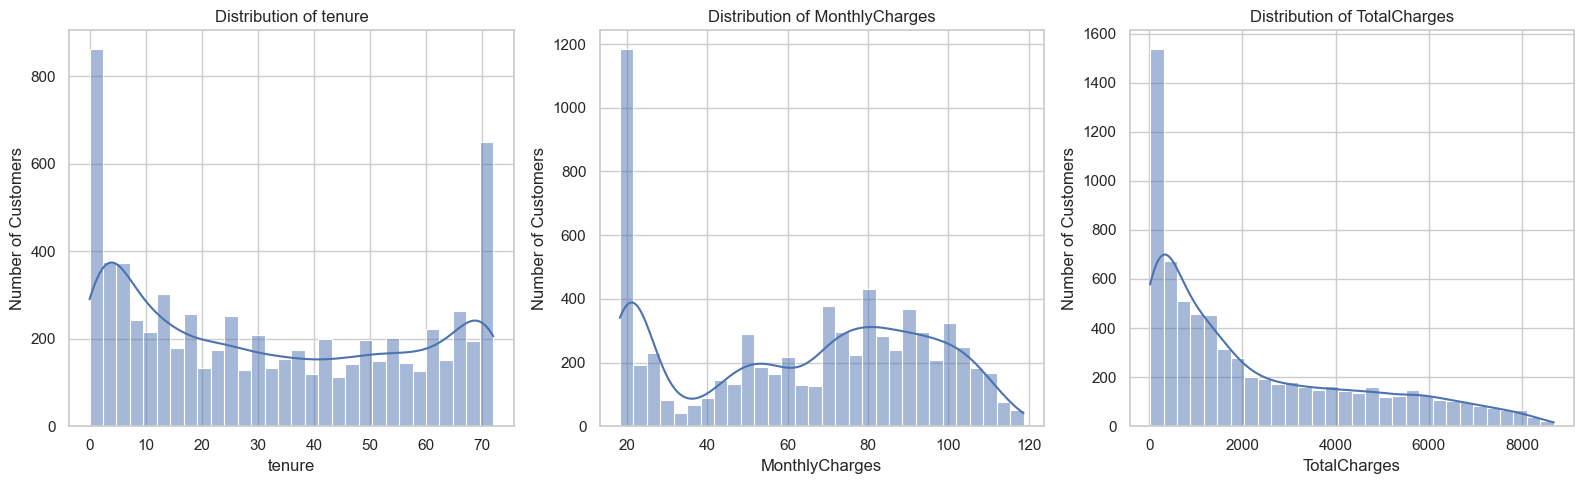

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, numerical_cols):
    sns.histplot(data=df, x=col, bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## 3. Phân phối các lớp khách hàng rời bỏ (Churn Class Distribution)

Phần này xem xét sự phân phối của biến mục tiêu nhằm xác định tình trạng mất cân bằng giữa các lớp (nếu có).

,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


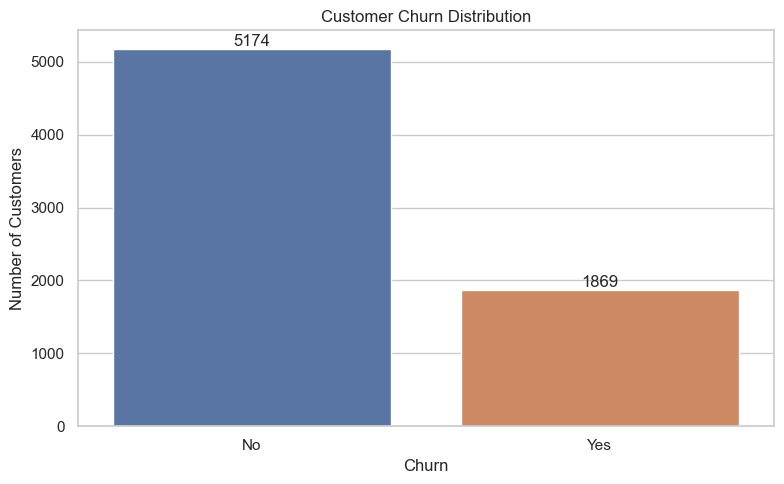

In [8]:
churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    "Count": churn_counts,
    "Percentage": churn_percentages
})

display(churn_summary)

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(data=df, x="Churn", hue="Churn", legend=False, ax=ax)

ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [9]:
class_ratio = churn_counts["No"] / churn_counts["Yes"]

print(f"Churn rate: {churn_percentages['Yes']:.2f}%")
print(f"Non-churn rate: {churn_percentages['No']:.2f}%")
print(f"Class imbalance ratio: {class_ratio:.2f}:1")

Churn rate: 26.54%
Non-churn rate: 73.46%
Class imbalance ratio: 2.77:1


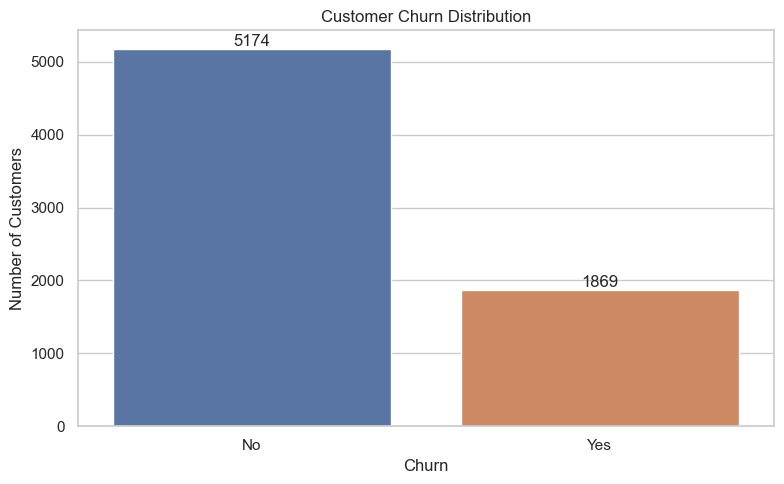

In [10]:
FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(data=df, x="Churn", hue="Churn", legend=False, ax=ax)

ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "churn_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Phân tích nhân khẩu học

Phần này nghiên cứu mối quan hệ giữa các đặc điểm nhân khẩu học
và tỷ lệ khách hàng rời bỏ.

Phân tích tập trung vào:

- Giới tính
- Người cao tuổi
- Vợ/chồng
- Người phụ thuộc

In [11]:
def analyze_churn_by_category(data, column):
    summary = (
        data.groupby(column, observed=True)["Churn"]
        .agg(
            Total_Customers="count",
            Churned_Customers=lambda x: (x == "Yes").sum()
        )
    )

    summary["Churn_Rate"] = (
        summary["Churned_Customers"]
        / summary["Total_Customers"]
        * 100
    )

    return summary

,Total_Customers,Churned_Customers,Churn_Rate
gender,,,
Female,3488,939,26.92
Male,3555,930,26.16


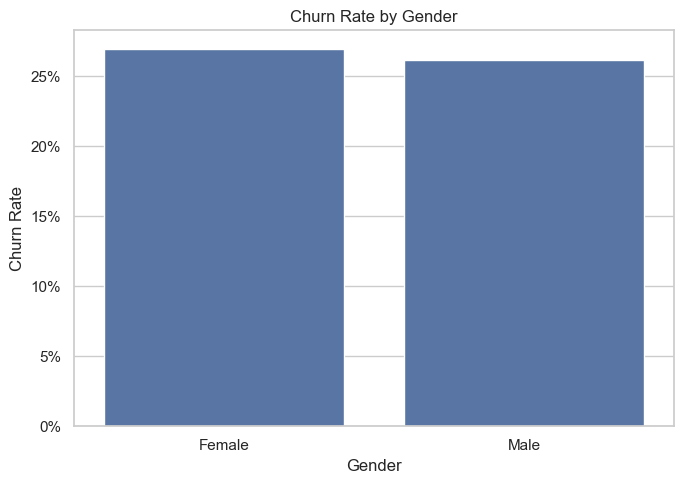

In [12]:
gender_summary = analyze_churn_by_category(df, "gender")

display(gender_summary)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="gender",
    y=df["Churn"].eq("Yes").astype(int),
    estimator="mean",
    errorbar=None
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

,Total_Customers,Churned_Customers,Churn_Rate
SeniorCitizen,,,
Non-Senior Citizen,5901,1393,23.61
Senior Citizen,1142,476,41.68


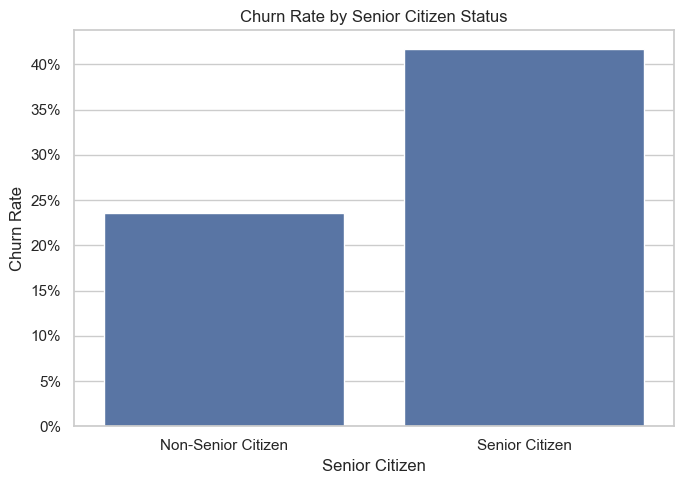

In [13]:
senior_summary = analyze_churn_by_category(df, "SeniorCitizen")

senior_summary.index = senior_summary.index.map({
    0: "Non-Senior Citizen",
    1: "Senior Citizen"
})

display(senior_summary)

plot_df = df.copy()
plot_df["SeniorCitizen"] = plot_df["SeniorCitizen"].map({
    0: "Non-Senior Citizen",
    1: "Senior Citizen"
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=plot_df,
    x="SeniorCitizen",
    y=plot_df["Churn"].eq("Yes").astype(int),
    estimator="mean",
    errorbar=None
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

,Total_Customers,Churned_Customers,Churn_Rate
Partner,,,
No,3641,1200,32.96
Yes,3402,669,19.66


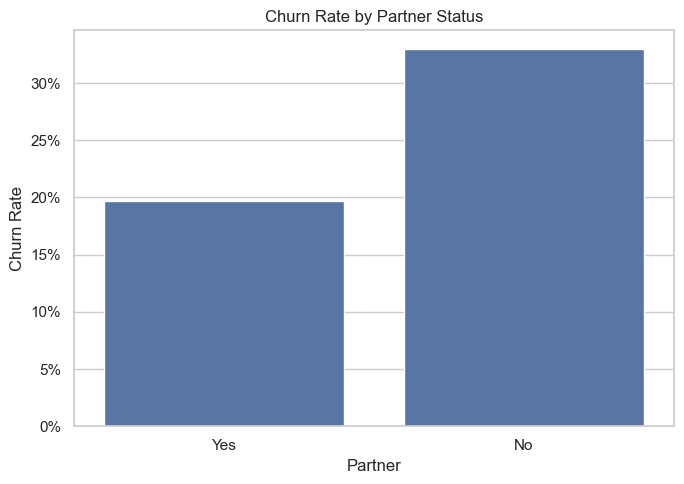

In [14]:
partner_summary = analyze_churn_by_category(df, "Partner")

display(partner_summary)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Partner",
    y=df["Churn"].eq("Yes").astype(int),
    estimator="mean",
    errorbar=None
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

,Total_Customers,Churned_Customers,Churn_Rate
Dependents,,,
No,4933,1543,31.28
Yes,2110,326,15.45


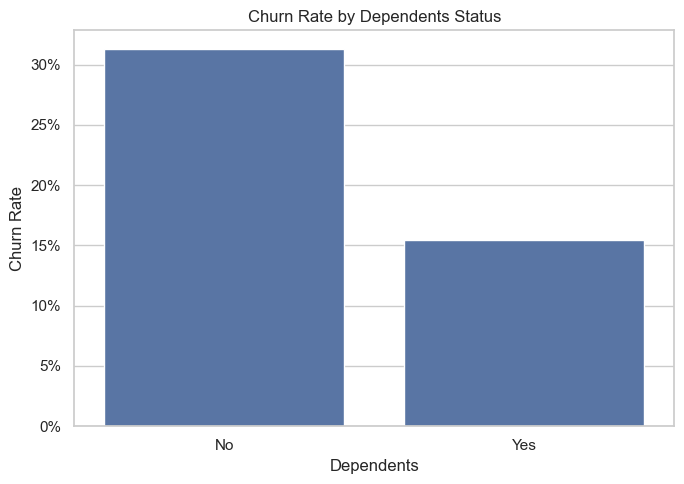

In [15]:
dependents_summary = analyze_churn_by_category(df, "Dependents")

display(dependents_summary)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Dependents",
    y=df["Churn"].eq("Yes").astype(int),
    estimator="mean",
    errorbar=None
)

plt.title("Churn Rate by Dependents Status")
plt.xlabel("Dependents")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

In [16]:
demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

for col in demographic_columns:
    plot_data = df.copy()

    if col == "SeniorCitizen":
        plot_data[col] = plot_data[col].map({
            0: "Non-Senior Citizen",
            1: "Senior Citizen"
        })

    plot_data["Churn_Flag"] = plot_data["Churn"].eq("Yes").astype(int)

    fig, ax = plt.subplots(figsize=(7, 5))

    sns.barplot(
        data=plot_data,
        x=col,
        y="Churn_Flag",
        estimator="mean",
        errorbar=None,
        ax=ax
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Churn Rate")
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y:.0%}")
    )

    plt.tight_layout()
    fig.savefig(
        FIGURE_DIR / f"churn_by_{col.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

In [18]:
demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

all_summaries = []

for col in demographic_columns:
    summary = analyze_churn_by_category(df, col).reset_index()

    summary.columns = [
        "Category",
        "Total_Customers",
        "Churned_Customers",
        "Churn_Rate"
    ]

    if col == "SeniorCitizen":
        summary["Category"] = summary["Category"].map({
            0: "Non-Senior Citizen",
            1: "Senior Citizen"
        })

    summary.insert(0, "Feature", col)

    all_summaries.append(summary)

demographic_results = pd.concat(
    all_summaries,
    ignore_index=True
)

display(demographic_results)

,Feature,Category,Total_Customers,Churned_Customers,Churn_Rate
0,gender,Female,3488,939,26.92
1,gender,Male,3555,930,26.16
2,SeniorCitizen,Non-Senior Citizen,5901,1393,23.61
3,SeniorCitizen,Senior Citizen,1142,476,41.68
4,Partner,No,3641,1200,32.96
5,Partner,Yes,3402,669,19.66
6,Dependents,No,4933,1543,31.28
7,Dependents,Yes,2110,326,15.45


## 6. Kiểm định ý nghĩa thống kê

Kiểm định Chi-bình phương về tính độc lập được sử dụng để xem xét
liệu các đặc điểm nhân khẩu học có mối liên hệ mang ý nghĩa thống kê với tình trạng khách hàng rời bỏ dịch vụ hay không.

Mức ý nghĩa được thiết lập ở giá trị 0,05.

In [19]:
from scipy.stats import chi2_contingency

demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

chi_square_results = []

for col in demographic_columns:
    contingency_table = pd.crosstab(df[col], df["Churn"])

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_square_results.append({
        "Feature": col,
        "Chi2_Statistic": chi2,
        "Degrees_of_Freedom": dof,
        "P_Value": p_value,
        "Significant": p_value < 0.05
    })

chi_square_df = pd.DataFrame(chi_square_results)

display(chi_square_df)

cramers_results = []

for col in demographic_columns:
    contingency_table = pd.crosstab(df[col], df["Churn"])

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    r, c = contingency_table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

    cramers_results.append({
        "Feature": col,
        "Chi2_Statistic": chi2,
        "P_Value": p_value,
        "Cramers_V": cramers_v
    })

cramers_df = pd.DataFrame(cramers_results)

display(
    cramers_df.sort_values(
        "Cramers_V",
        ascending=False
    )
)

,Feature,Chi2_Statistic,Degrees_of_Freedom,P_Value,Significant
0,gender,0.48,1,0.49,False
1,SeniorCitizen,159.43,1,0.00,True
2,Partner,158.73,1,0.00,True
3,Dependents,189.13,1,0.00,True


,Feature,Chi2_Statistic,P_Value,Cramers_V
3,Dependents,189.13,0.00,0.16
1,SeniorCitizen,159.43,0.00,0.15
2,Partner,158.73,0.00,0.15
0,gender,0.48,0.49,0.01


In [20]:
risk_results = []

for col in demographic_columns:
    groups = df.groupby(col, observed=True)

    categories = list(groups.groups.keys())

    for category in categories:
        group = groups.get_group(category)

        churned = (group["Churn"] == "Yes").sum()
        total = len(group)
        not_churned = total - churned

        other = df[df[col] != category]

        other_churned = (other["Churn"] == "Yes").sum()
        other_total = len(other)
        other_not_churned = other_total - other_churned

        risk = churned / total
        reference_risk = other_churned / other_total

        risk_difference = (risk - reference_risk) * 100
        relative_risk = risk / reference_risk

        odds_ratio = (
            (churned / not_churned)
            / (other_churned / other_not_churned)
        )

        risk_results.append({
            "Feature": col,
            "Category": category,
            "Churn_Rate": risk * 100,
            "Reference_Churn_Rate": reference_risk * 100,
            "Risk_Difference_pp": risk_difference,
            "Relative_Risk": relative_risk,
            "Odds_Ratio": odds_ratio
        })

risk_df = pd.DataFrame(risk_results)

display(
    risk_df.round(3)
)

,Feature,Category,Churn_Rate,Reference_Churn_Rate,Risk_Difference_pp,Relative_Risk,Odds_Ratio
0,gender,Female,26.92,26.16,0.76,1.03,1.04
1,gender,Male,26.16,26.92,-0.76,0.97,0.96
2,SeniorCitizen,0,23.61,41.68,-18.07,0.57,0.43
3,SeniorCitizen,1,41.68,23.61,18.07,1.77,2.31
4,Partner,No,32.96,19.66,13.29,1.68,2.01
5,Partner,Yes,19.66,32.96,-13.29,0.60,0.50
6,Dependents,No,31.28,15.45,15.83,2.02,2.49
7,Dependents,Yes,15.45,31.28,-15.83,0.49,0.40


,Feature,Category,Customer_Count,Customer_Share,Churned_Count,Churn_Contribution,Churn_Rate
0,gender,Female,3488,49.52,939,50.24,26.92
1,gender,Male,3555,50.48,930,49.76,26.16
2,SeniorCitizen,0,5901,83.79,1393,74.53,23.61
3,SeniorCitizen,1,1142,16.21,476,25.47,41.68
4,Partner,Yes,3402,48.30,669,35.79,19.66
5,Partner,No,3641,51.70,1200,64.21,32.96
6,Dependents,No,4933,70.04,1543,82.56,31.28
7,Dependents,Yes,2110,29.96,326,17.44,15.45


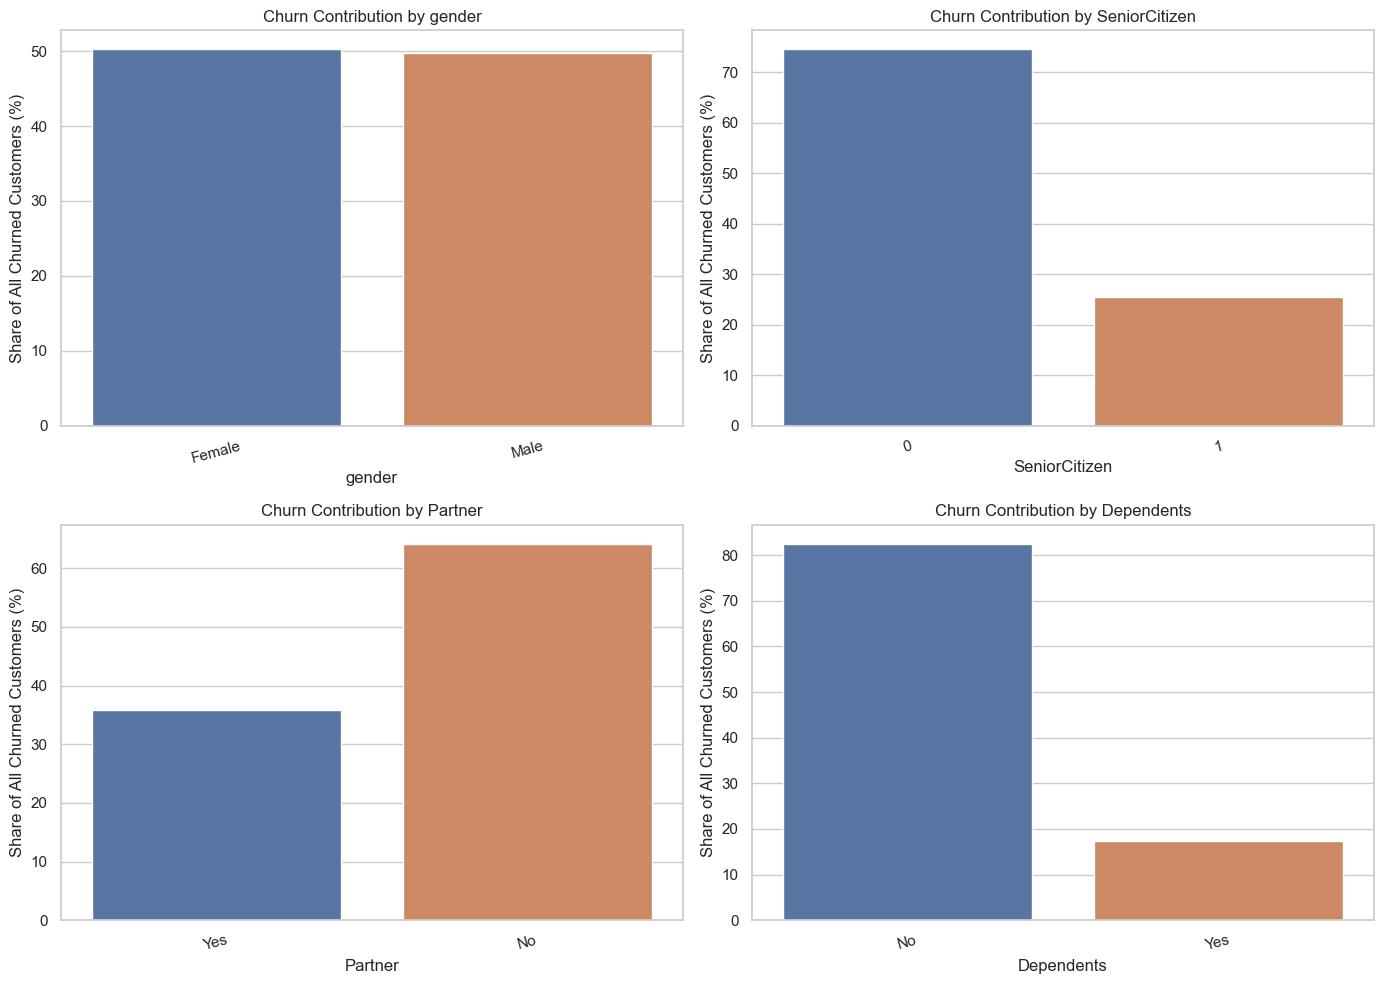

In [22]:
composition_results = []

for col in demographic_columns:
    for category in df[col].unique():
        group = df[df[col] == category]

        total_customers = len(group)
        churned_customers = (group["Churn"] == "Yes").sum()

        composition_results.append({
            "Feature": col,
            "Category": category,
            "Customer_Count": total_customers,
            "Customer_Share": total_customers / len(df) * 100,
            "Churned_Count": churned_customers,
            "Churn_Contribution": (
                churned_customers
                / (df["Churn"] == "Yes").sum()
                * 100
            ),
            "Churn_Rate": (
                churned_customers / total_customers * 100
            )
        })

composition_df = pd.DataFrame(composition_results)

display(composition_df.round(2))


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), demographic_columns):
    plot_data = composition_df[
        composition_df["Feature"] == col
    ]

    sns.barplot(
        data=plot_data,
        x="Category",
        y="Churn_Contribution",
        hue="Category",
        legend=False,
        ax=ax
    )

    ax.set_title(f"Churn Contribution by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Share of All Churned Customers (%)")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

,SeniorCitizen,Partner,Dependents,Total_Customers,Churned_Customers,Churn_Rate
4,1,No,No,561,276,49.20
6,1,Yes,No,490,178,36.33
0,0,No,No,2719,847,31.15
5,1,No,Yes,8,2,25.00
7,1,Yes,Yes,83,20,24.10
1,0,No,Yes,353,75,21.25
2,0,Yes,No,1163,242,20.81
3,0,Yes,Yes,1666,229,13.75


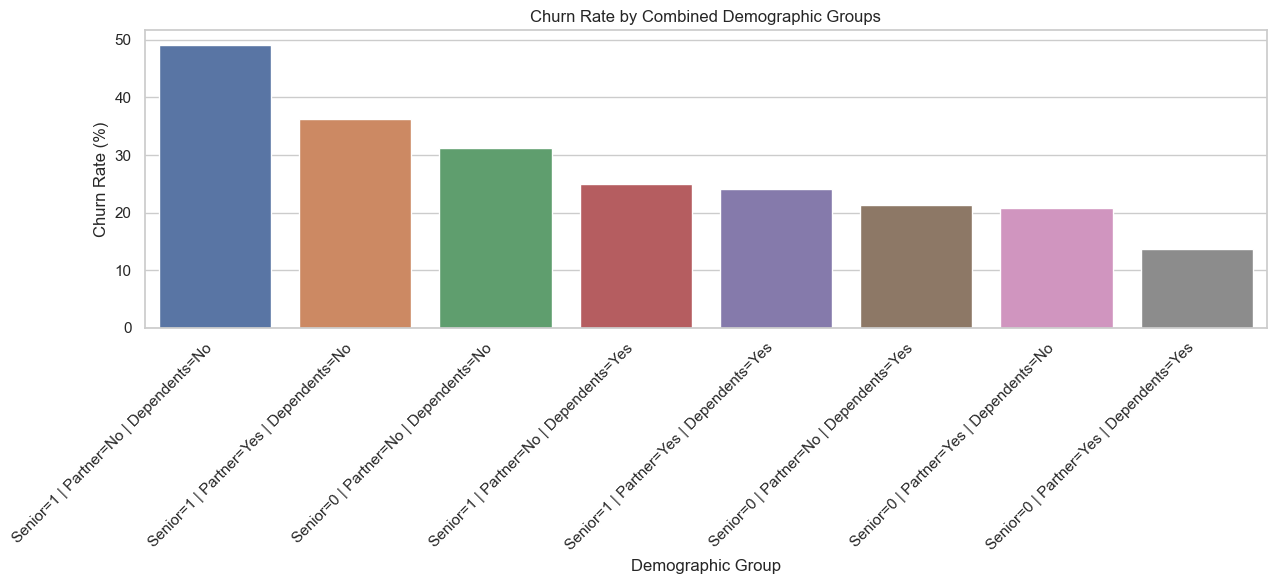

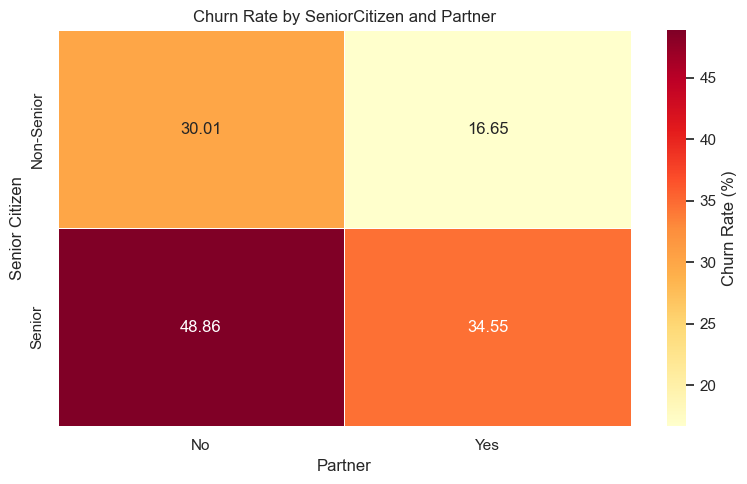

In [23]:
group_analysis = (
    df.groupby(
        ["SeniorCitizen", "Partner", "Dependents"],
        observed=True
    )
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=(
            "Churn",
            lambda x: (x == "Yes").sum()
        )
    )
    .reset_index()
)

group_analysis["Churn_Rate"] = (
    group_analysis["Churned_Customers"]
    / group_analysis["Total_Customers"]
    * 100
)

group_analysis = group_analysis.sort_values(
    "Churn_Rate",
    ascending=False
)

display(group_analysis.round(2)) 

group_analysis["Demographic_Group"] = (
    "Senior=" + group_analysis["SeniorCitizen"].astype(str)
    + " | Partner=" + group_analysis["Partner"]
    + " | Dependents=" + group_analysis["Dependents"]
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=group_analysis,
    x="Demographic_Group",
    y="Churn_Rate",
    hue="Demographic_Group",
    legend=False
)

plt.title("Churn Rate by Combined Demographic Groups")
plt.xlabel("Demographic Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

heatmap_data = df.pivot_table(
    index="SeniorCitizen",
    columns="Partner",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100
)

heatmap_data.index = [
    "Non-Senior",
    "Senior"
]

plt.figure(figsize=(8, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"}
)

plt.title("Churn Rate by SeniorCitizen and Partner")
plt.xlabel("Partner")
plt.ylabel("Senior Citizen")

plt.tight_layout()
plt.show()

In [26]:
from scipy.stats import false_discovery_control

chi_square_df["Adjusted_P_Value"] = (
    false_discovery_control(
        chi_square_df["P_Value"].values,
        method="bh"
    )
)

display(chi_square_df)

,Feature,Chi2_Statistic,Degrees_of_Freedom,P_Value,Significant,Adjusted_P_Value
0,gender,0.48,1,0.49,False,0.49
1,SeniorCitizen,159.43,1,0.00,True,0.00
2,Partner,158.73,1,0.00,True,0.00
3,Dependents,189.13,1,0.00,True,0.00


In [28]:
from statsmodels.stats.multitest import multipletests

chi_square_df["Adjusted_P_Value"] = multipletests(
    chi_square_df["P_Value"],
    method="holm"
)[1]

display(chi_square_df)

,Feature,Chi2_Statistic,Degrees_of_Freedom,P_Value,Significant,Adjusted_P_Value
0,gender,0.48,1,0.49,False,0.49
1,SeniorCitizen,159.43,1,0.00,True,0.00
2,Partner,158.73,1,0.00,True,0.00
3,Dependents,189.13,1,0.00,True,0.00


## 7. Tổng kết và kết luận EDA

### 7.1. Tổng quan dữ liệu

Tập dữ liệu bao gồm 7.043 khách hàng với 21 đặc trưng, cung cấp thông tin về nhân khẩu học, dịch vụ sử dụng, hợp đồng và chi phí của khách hàng.

### 7.2. Phân tích phân phối nhãn Churn

Kết quả phân tích cho thấy dữ liệu có sự mất cân bằng giữa hai nhóm khách hàng:

- Khách hàng không rời bỏ dịch vụ (No Churn): 5.174 người, chiếm 73,46%.
- Khách hàng rời bỏ dịch vụ (Churn): 1.869 người, chiếm 26,54%.

Tỷ lệ mất cân bằng giữa hai lớp xấp xỉ 2,77:1. Điều này cần được lưu ý trong quá trình xây dựng và đánh giá mô hình dự đoán Churn.

### 7.3. Phân tích mối liên hệ giữa nhân khẩu học và Churn

Kết quả phân tích cho thấy tỷ lệ rời bỏ dịch vụ có sự khác biệt giữa các nhóm khách hàng:

- **Giới tính (Gender):** Khách hàng nữ có tỷ lệ Churn là 26,92%, trong khi khách hàng nam là 26,16%. Sự khác biệt giữa hai nhóm khá nhỏ
- **Người cao tuổi (SeniorCitizen):** Nhóm khách hàng cao tuổi có tỷ lệ Churn là 41,68%, cao hơn nhóm không cao tuổi (23,61%).
- **Bạn đời (Partner):** Khách hàng không có bạn đời có tỷ lệ Churn là 32,96%, cao hơn nhóm có bạn đời (19,66%).
- **Người phụ thuộc (Dependents):** Khách hàng không có người phụ thuộc có tỷ lệ Churn là 31,28%, cao hơn nhóm có người phụ thuộc (15,45%).

### 7.4. Kết quả kiểm định thống kê

Kiểm định Chi-square(phương pháp xem 2 biến có liên quan đến nhau không) cho thấy có mối liên hệ có ý nghĩa thống kê giữa Churn với ba đặc trưng: SeniorCitizen, Partner và Dependents.

Trong khi đó, Gender không cho thấy mối liên hệ có ý nghĩa thống kê với Churn.

Kết quả Cramér's V(nếu có liên quan thì mạnh hay yếu) cho thấy mức độ liên kết giữa các đặc trưng nhân khẩu học và Churn tương đối yếu.

### 7.5. Kết luận

Các đặc trưng nhân khẩu học cung cấp những thông tin hữu ích để nhận diện sự khác biệt về hành vi rời bỏ dịch vụ giữa các nhóm khách hàng.

Trong đó, SeniorCitizen, Partner và Dependents có mối liên hệ có ý nghĩa thống kê với Churn, còn Gender chưa thấy mối liên hệ đáng kể.

Tuy nhiên, các đặc trưng nhân khẩu học không đủ để giải thích toàn bộ hành vi rời bỏ dịch vụ của khách hàng. Do đó, cần xem xét thêm các nhóm đặc trưng khác trong những giai đoạn phân tích và xây dựng mô hình tiếp theo.